In [12]:
import os
from itertools import cycle

import numpy as np
import torch
import matplotlib.pyplot as plt

from constants import *

Plot saved at ./assets/eigvals_error_shallow.png


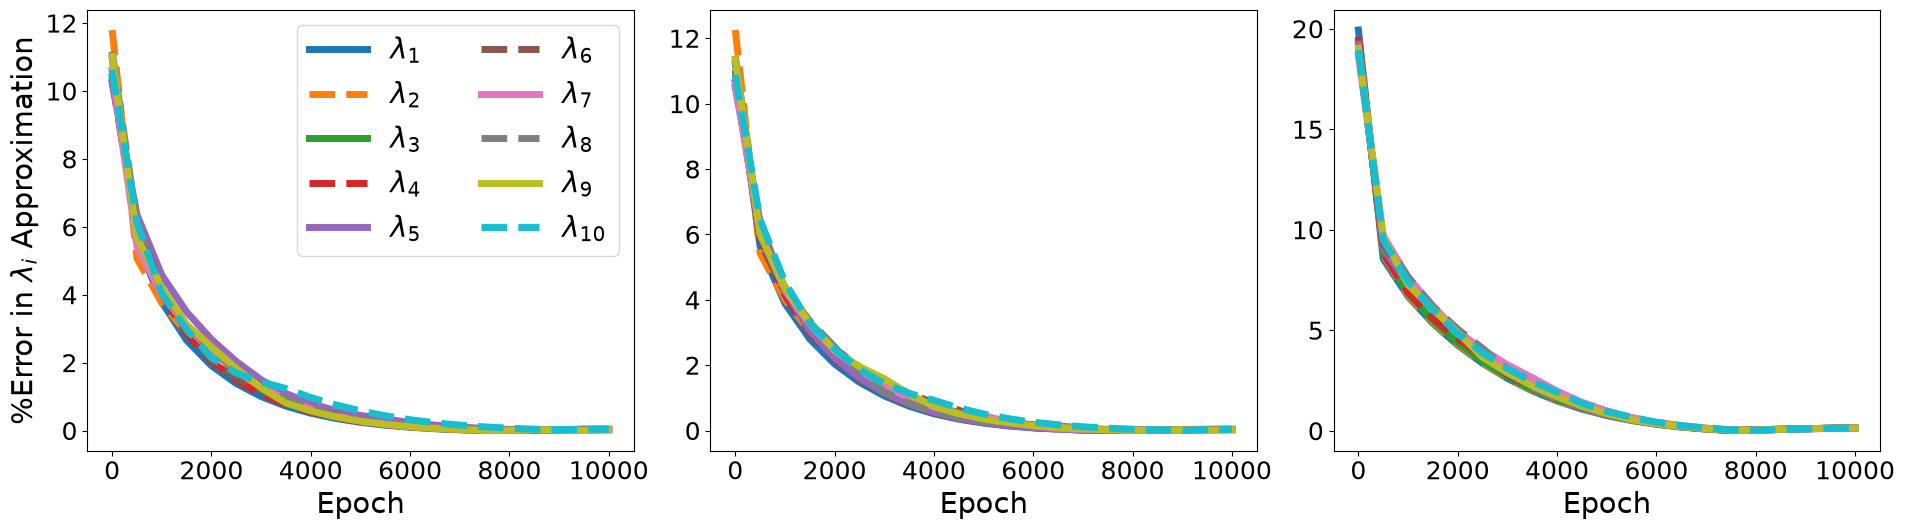

In [13]:
from eigvals_error_shallow import *
source_name = "eigvals_error_shallow"
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")
N_EIGS = 10

fig, axs = plt.subplots(1, len(DATASETS), figsize=(AX_WIDTH*len(DATASETS), AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))

for Dataset, ax in zip(DATASETS, axs):

    fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
    results = torch.load(fn, weights_only=False, map_location="cpu")
    kwargs, assets, out = results["kwargs"], results["assets"], results["out"]

    *_, numerical_eigvals, theoretical_eigvals = out
    linestyles = cycle(["-", "--"])
    for i in range(min(theoretical_eigvals.shape[1], N_EIGS)):
        ax.plot(
            LOG_EVERY*np.arange(0, len(numerical_eigvals)),
            100*np.abs(1-theoretical_eigvals[:,i]/numerical_eigvals[:,i]),
            linewidth=LINE_WIDTH, linestyle=next(linestyles), label=rf"$\lambda_{{{i+1}}}$"
        )
    ax.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax.set_xlabel("Epoch", fontsize=FONT_SIZE)
    # ax.grid()

axs[0].set_ylabel(r"%Error in $\lambda_{{i}}$ Approximation", fontsize=FONT_SIZE)
axs[0].legend(loc="upper right", ncol=2, fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/eigvals_error_deep.png


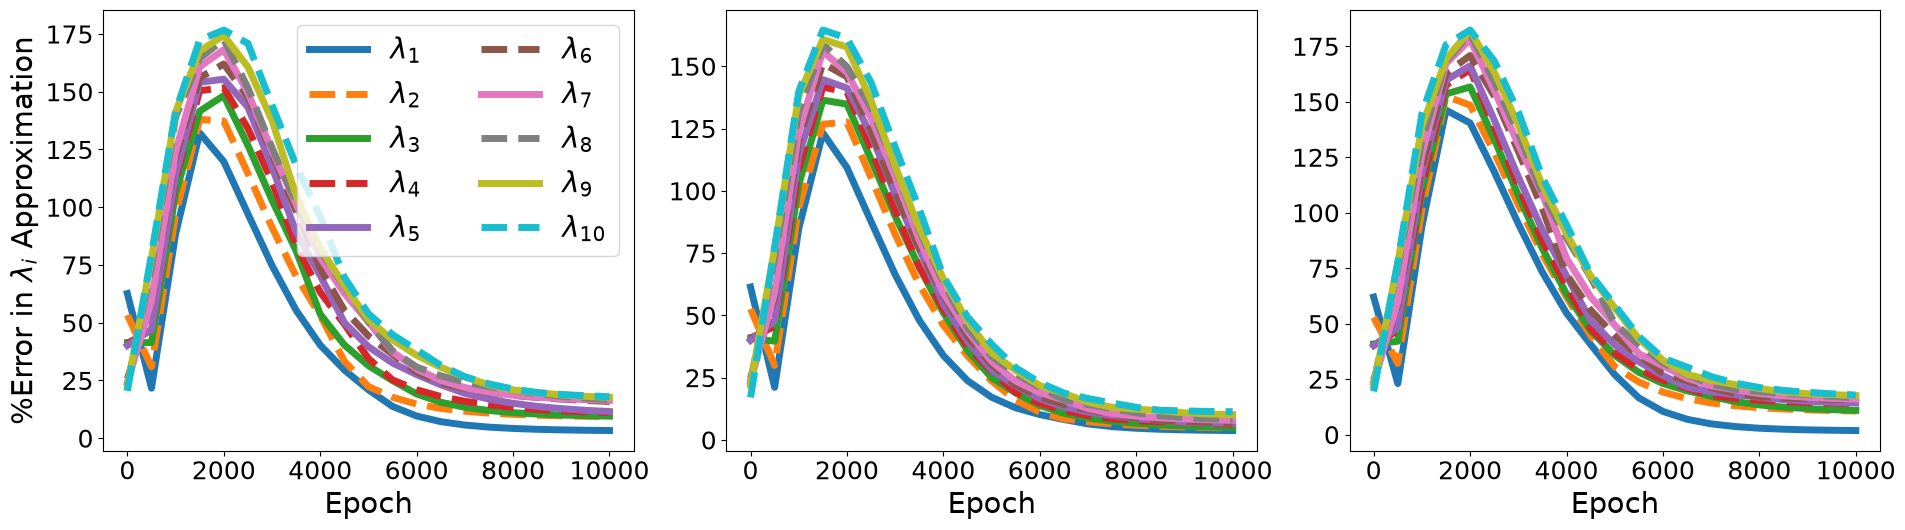

In [14]:
from eigvals_error_deep import *
source_name = "eigvals_error_deep"
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")
N_EIGS = 10

fig, axs = plt.subplots(1, len(DATASETS), figsize=(AX_WIDTH*len(DATASETS), AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))

for Dataset, ax in zip(DATASETS, axs):

    fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
    results = torch.load(fn, weights_only=False, map_location="cpu")
    kwargs, assets, out = results["kwargs"], results["assets"], results["out"]

    *_, numerical_eigvals, theoretical_eigvals = out
    linestyles = cycle(["-", "--"])
    for i in range(min(theoretical_eigvals.shape[1], N_EIGS)):
        ax.plot(
            LOG_EVERY*np.arange(0, len(numerical_eigvals)),
            100*np.abs(1-theoretical_eigvals[:,i]/numerical_eigvals[:,i]),
            linewidth=LINE_WIDTH, linestyle=next(linestyles), label=rf"$\lambda_{{{i+1}}}$"
        )
    ax.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax.set_xlabel("Epoch", fontsize=FONT_SIZE)
    # ax.grid()

axs[0].set_ylabel(r"%Error in $\lambda_{{i}}$ Approximation", fontsize=FONT_SIZE)
axs[0].legend(loc="upper right", ncol=2, fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/comparing_bounds_shallow.png


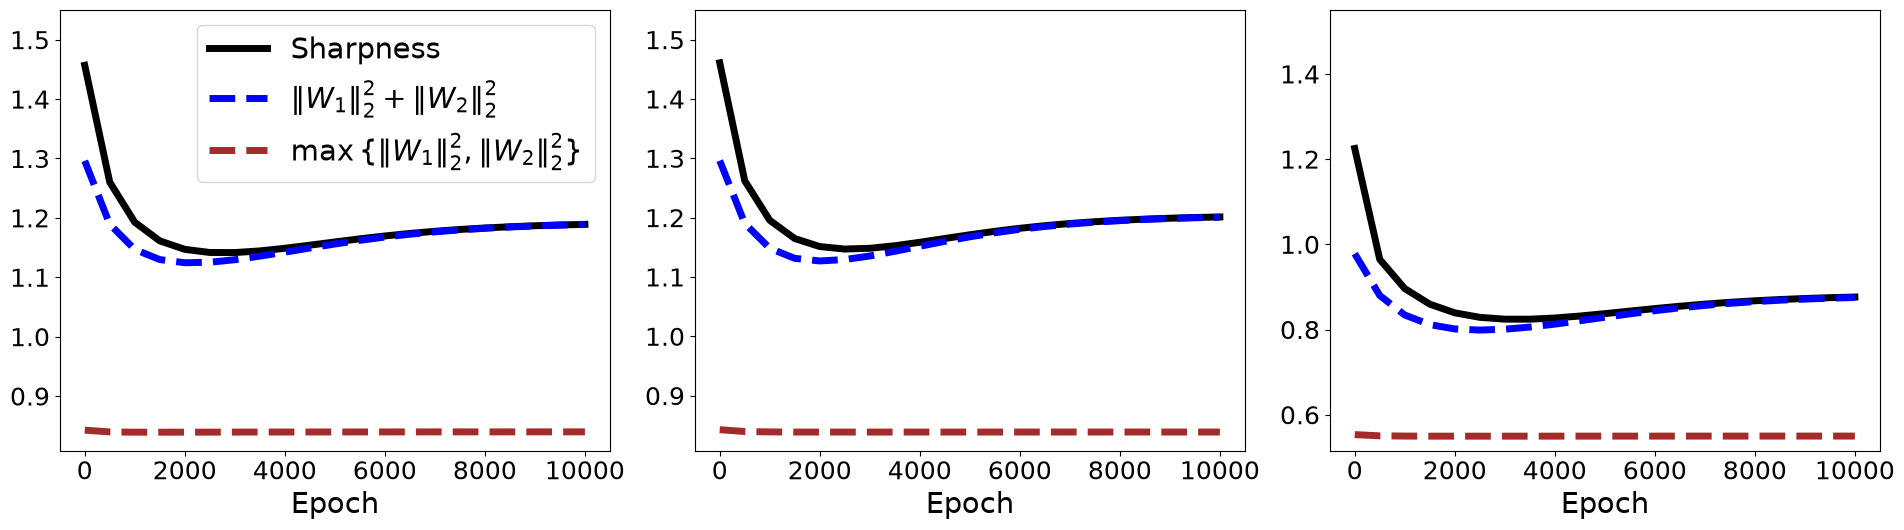

In [15]:
from comparing_bounds_shallow import *
source_name = "comparing_bounds_shallow"
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")

fig, axs = plt.subplots(1, len(DATASETS), figsize=(AX_WIDTH*len(DATASETS), AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))

for Dataset, ax in zip(DATASETS, axs):

    fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
    results = torch.load(fn, weights_only=False, map_location="cpu")
    kwargs, assets, out = results["kwargs"], results["assets"], results["out"]

    *_, numerical_eigvals, theoretical_eigvals = out
    ax.plot(
        LOG_EVERY*np.arange(0, len(numerical_eigvals)),
        numerical_eigvals,
        linewidth=LINE_WIDTH, color="black", label="Sharpness"
    )
    ax.plot(
        LOG_EVERY*np.arange(0, len(theoretical_eigvals)),
        theoretical_eigvals[:,0],
        linewidth=LINE_WIDTH, linestyle="--", color="blue",
        label=r"$\|W_1\|_2^2+\|W_2\|_2^2$"
    )
    ax.plot(
        LOG_EVERY*np.arange(0, len(theoretical_eigvals)),
        theoretical_eigvals[:,1],
        linewidth=LINE_WIDTH, linestyle="--", color="brown",
        label=r"$\max\{\|W_1\|_2^2, \|W_2\|_2^2\}$"
    )
    ax.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax.set_ylim(top=1.55)
    ax.set_xlabel("Epoch", fontsize=FONT_SIZE)
    # ax.grid()

axs[0].legend(loc="upper right", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/sharpness_vs_param_norm.png


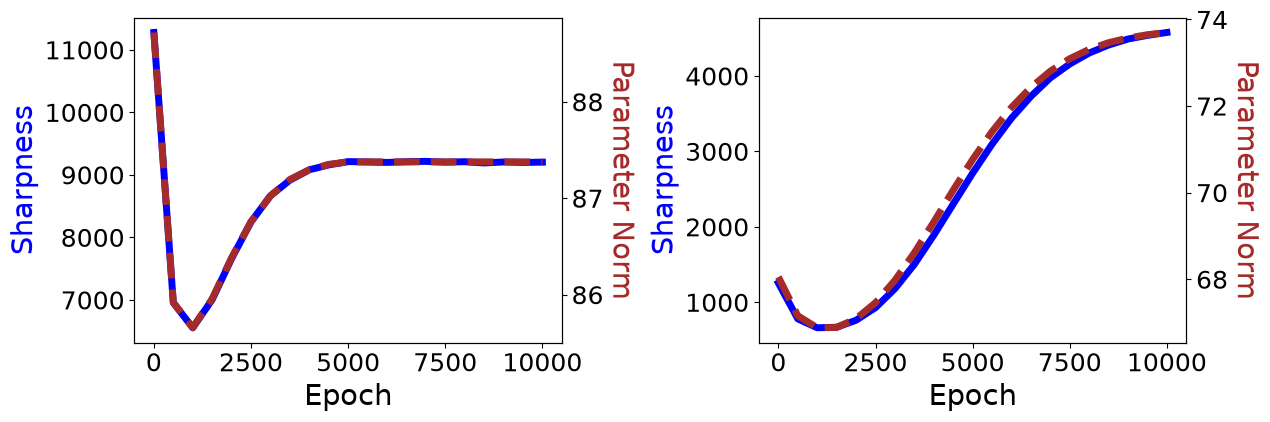

In [16]:
from sharpness_vs_param_norm import *
source_name = "sharpness_vs_param_norm"
SAVE_NAMES = ("wide-shallow", "narrow-deep")

fig, axs = plt.subplots(1, len(SAVE_NAMES), figsize=(AX_WIDTH*len(SAVE_NAMES), 0.8*AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))

for save_name, ax in zip(SAVE_NAMES, axs):

    fn = f"{RESULTS}/{source_name}/{save_name}.pt"
    results = torch.load(fn, weights_only=False, map_location="cpu")
    kwargs, assets, out = results["kwargs"], results["assets"], results["out"]

    *_, sq_param_norms, numerical_eigvals = out
    p = ax.plot(
        LOG_EVERY*np.arange(0, len(numerical_eigvals)),
        numerical_eigvals,
        linestyle="-", linewidth=LINE_WIDTH, color="blue"
    )
    ax.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax.set_xlabel("Epoch", fontsize=FONT_SIZE)
    ax.set_ylabel("Sharpness", fontsize=FONT_SIZE, color=p[-1].get_color())
    # ax.grid()
    ax_twin = ax.twinx()
    p = ax_twin.plot(
        LOG_EVERY*np.arange(0, len(sq_param_norms)),
        sq_param_norms.sum(axis=1),
        linestyle="--", linewidth=LINE_WIDTH, color="brown"
    )
    ax_twin.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax_twin.set_ylabel("Parameter Norm", fontsize=FONT_SIZE, color=p[-1].get_color(), rotation=270, labelpad=FONT_SIZE+2)

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/sharpness_balanced_init.png


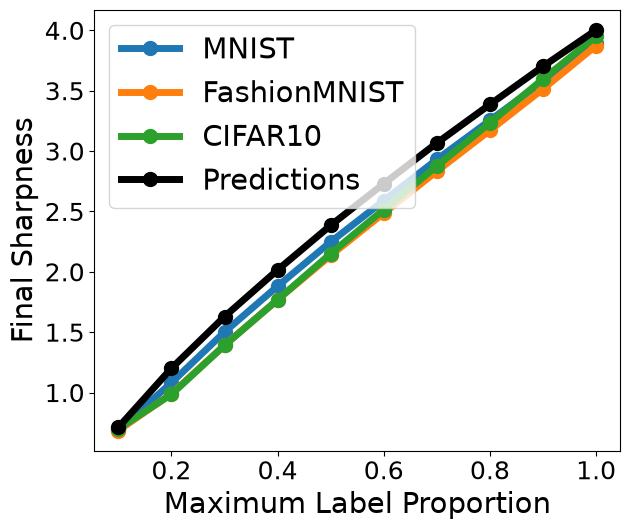

In [17]:
from sharpness_balanced_init import *
source_name = "sharpness_balanced_init"
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")
MAX_PROPS = np.linspace(0.1, 1.0, 10)

fig, ax = plt.subplots(1, 1, figsize=(AX_WIDTH*1, AX_HEIGHT*1))

for Dataset in DATASETS:
    numerical_eigvals, theoretical_eigvals = list(), list()
    for max_prop in MAX_PROPS:
        fn = f"{RESULTS}/{source_name}/{Dataset.lower()}/max_prop={max_prop:.1f}.pt"
        results = torch.load(fn, weights_only=False, map_location="cpu")
        kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
        *_, numerical_eigval, theoretical_eigval = out
        numerical_eigvals.append(numerical_eigval[-1].item())
        theoretical_eigvals.append(theoretical_eigval[-1].item())
    ax.plot(MAX_PROPS, numerical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, label=Dataset)
ax.plot(MAX_PROPS, theoretical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, color="black", label="Predictions")

ax.set_xticks(MAX_PROPS[1::2])
ax.tick_params(axis="both", labelsize=LABEL_SIZE)
ax.set_xlabel("Maximum Label Proportion", fontsize=FONT_SIZE)
ax.set_ylabel("Final Sharpness", fontsize=FONT_SIZE)
ax.legend(loc="upper left", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)
# ax.grid()

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/ablation_anisotropic_features.png


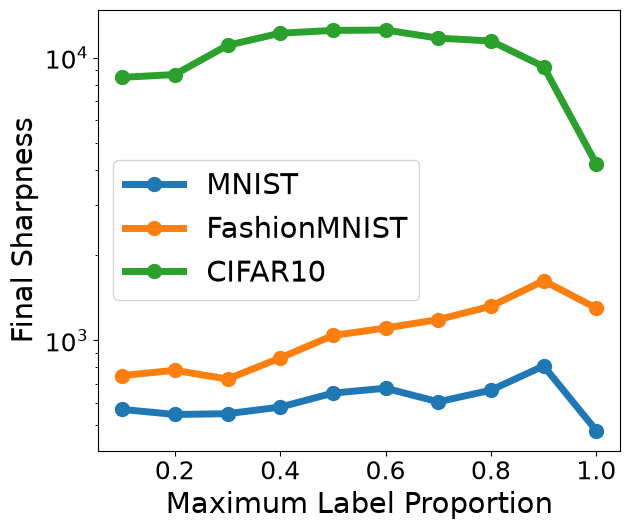

In [18]:
from ablation_anisotropic_features import *
source_name = "ablation_anisotropic_features"
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")
MAX_PROPS = np.linspace(0.1, 1.0, 10)

fig, ax = plt.subplots(1, 1, figsize=(AX_WIDTH*1, AX_HEIGHT*1))

for Dataset in DATASETS:
    numerical_eigvals, theoretical_eigvals = list(), list()
    for max_prop in MAX_PROPS:
        fn = f"{RESULTS}/{source_name}/{Dataset.lower()}/max_prop={max_prop:.1f}.pt"
        results = torch.load(fn, weights_only=False, map_location="cpu")
        kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
        *_, numerical_eigval, theoretical_eigval = out
        numerical_eigvals.append(numerical_eigval[-1].item())
        theoretical_eigvals.append(theoretical_eigval[-1].item())
    ax.plot(MAX_PROPS, numerical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, label=Dataset)

ax.set_xticks(MAX_PROPS[1::2])
ax.set_yscale("log")
ax.tick_params(axis="both", labelsize=LABEL_SIZE)
ax.set_xlabel("Maximum Label Proportion", fontsize=FONT_SIZE)
ax.set_ylabel("Final Sharpness", fontsize=FONT_SIZE)
ax.legend(loc="center left", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)
# ax.grid()

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/ablation_unbalanced_weights.png


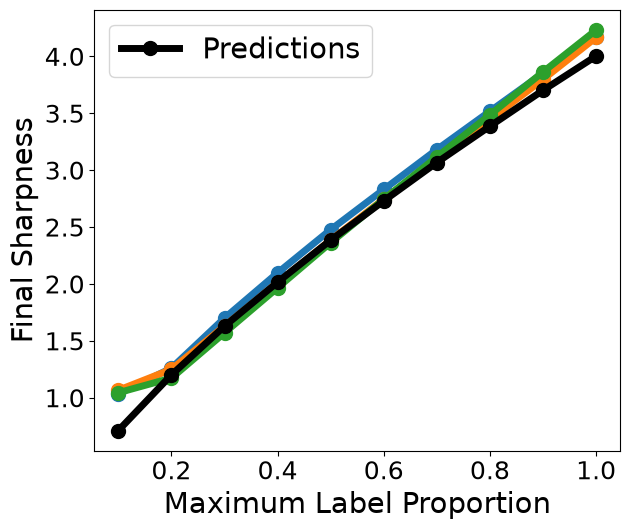

In [19]:
from ablation_unbalanced_weights import *
source_name = "ablation_unbalanced_weights"
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")
MAX_PROPS = np.linspace(0.1, 1.0, 10)

fig, ax = plt.subplots(1, 1, figsize=(AX_WIDTH*1, AX_HEIGHT*1))

for Dataset in DATASETS:
    numerical_eigvals, theoretical_eigvals = list(), list()
    for max_prop in MAX_PROPS:
        fn = f"{RESULTS}/{source_name}/{Dataset.lower()}/max_prop={max_prop:.1f}.pt"
        results = torch.load(fn, weights_only=False, map_location="cpu")
        kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
        *_, numerical_eigval, theoretical_eigval = out
        numerical_eigvals.append(numerical_eigval[-1].item())
        theoretical_eigvals.append(theoretical_eigval[-1].item())
    ax.plot(MAX_PROPS, numerical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE)
ax.plot(MAX_PROPS, theoretical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, color="black", label="Predictions")

ax.set_xticks(MAX_PROPS[1::2])
ax.tick_params(axis="both", labelsize=LABEL_SIZE)
ax.set_xlabel("Maximum Label Proportion", fontsize=FONT_SIZE)
ax.set_ylabel("Final Sharpness", fontsize=FONT_SIZE)
ax.legend(loc="upper left", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)
# ax.grid()

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/ablation_nonlinear_activation.png


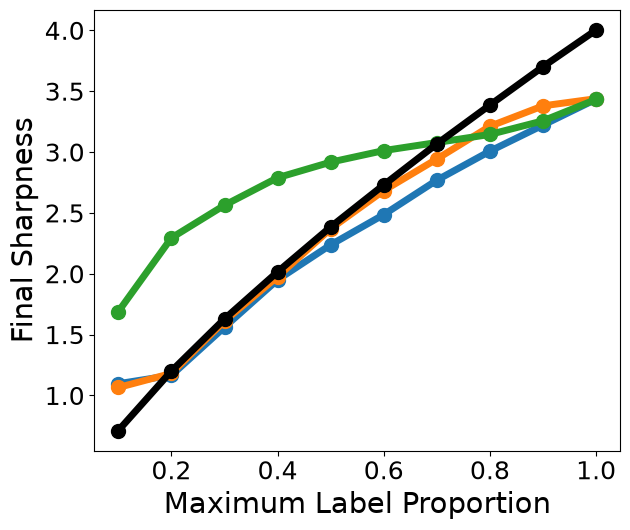

In [20]:
from ablation_nonlinear_activation import *
source_name = "ablation_nonlinear_activation"
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")
MAX_PROPS = np.linspace(0.1, 1.0, 10)

fig, ax = plt.subplots(1, 1, figsize=(AX_WIDTH*1, AX_HEIGHT*1))

for Dataset in DATASETS:
    numerical_eigvals, theoretical_eigvals = list(), list()
    for max_prop in MAX_PROPS:
        fn = f"{RESULTS}/{source_name}/{Dataset.lower()}/max_prop={max_prop:.1f}.pt"
        results = torch.load(fn, weights_only=False, map_location="cpu")
        kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
        *_, numerical_eigval, theoretical_eigval = out
        numerical_eigvals.append(numerical_eigval[-1].item())
        theoretical_eigvals.append(theoretical_eigval[-1].item())
    ax.plot(MAX_PROPS, numerical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, label=Dataset)
ax.plot(MAX_PROPS, theoretical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, color="black", label="Predictions")

ax.set_xticks(MAX_PROPS[1::2])
ax.tick_params(axis="both", labelsize=LABEL_SIZE)
ax.set_xlabel("Maximum Label Proportion", fontsize=FONT_SIZE)
ax.set_ylabel("Final Sharpness", fontsize=FONT_SIZE)
# ax.legend(loc="upper left", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)
# ax.grid()

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/effect_of_dataset_size.png


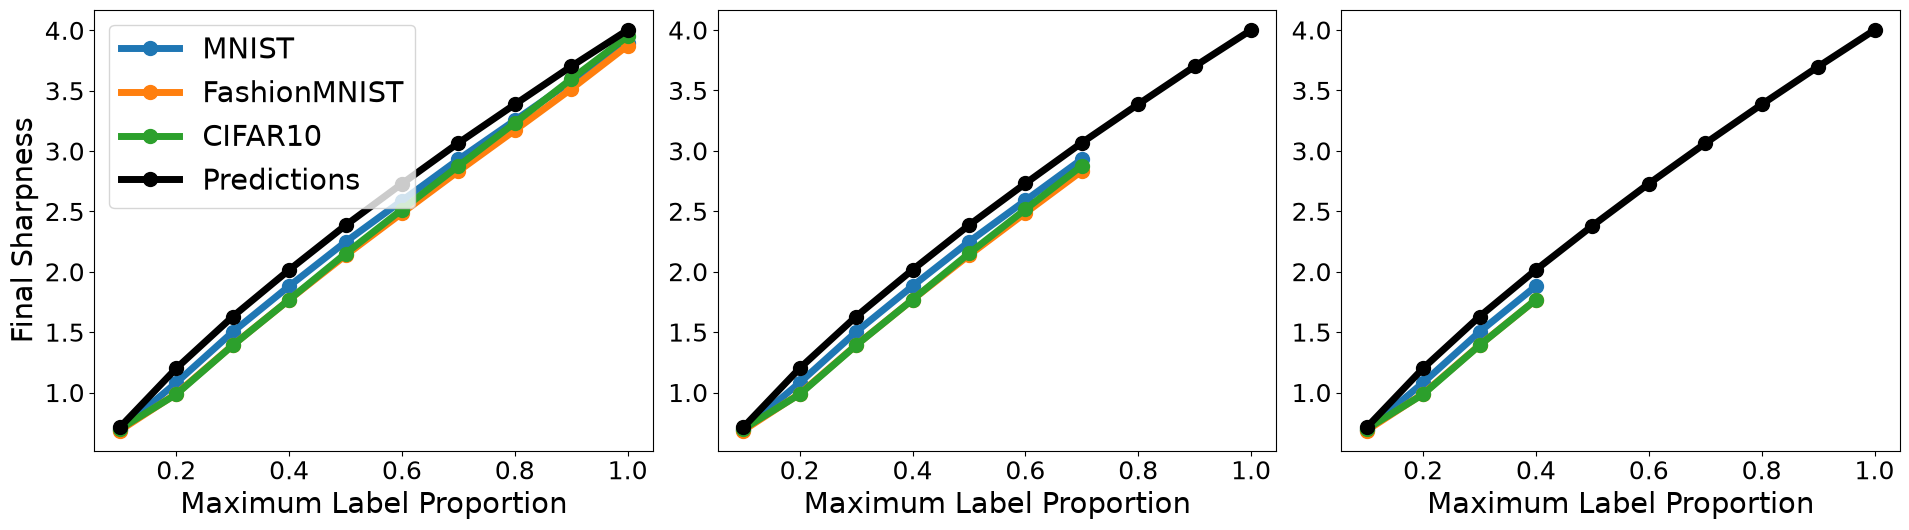

In [21]:
from effect_of_dataset_size import *
source_name = "effect_of_dataset_size"
SUBSET_SIZES = (4000, 7000, 10000)
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")
OUTPUT_DIMS = (10, 10, 10)
MAX_PROPS = np.linspace(0.1, 1.0, 10)
WIDTHS = NARROW_DEEP_WIDTHS

fig, axs = plt.subplots(1, len(SUBSET_SIZES), figsize=(AX_WIDTH*len(SUBSET_SIZES), AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))

for subset_size, ax in zip(SUBSET_SIZES, axs):
    for Dataset, output_dim in zip(DATASETS, OUTPUT_DIMS):
        numerical_eigvals, theoretical_eigvals = list(), list()
        for max_prop in MAX_PROPS:
            max_size = subset_size - int(subset_size*(1-max_prop)/(output_dim-1))*(output_dim-1)
            if max_size > 5000:
                numerical_eigvals.append(torch.nan)
                L = len(WIDTHS) + 1
                theoretical_eigvals.append(L*(max_size/subset_size)**(1-1/L))
                continue
            fn = f"{RESULTS}/{source_name}/n={subset_size}/{Dataset.lower()}/max_prop={max_prop:.1f}.pt"
            results = torch.load(fn, weights_only=False, map_location="cpu")
            kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
            *_, numerical_eigval, theoretical_eigval = out
            numerical_eigvals.append(numerical_eigval[-1].item())
            theoretical_eigvals.append(theoretical_eigval[-1].item())
        ax.plot(MAX_PROPS, numerical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, label=Dataset)
    ax.plot(MAX_PROPS, theoretical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, color="black", label="Predictions")
    ax.set_xticks(MAX_PROPS[1::2])
    ax.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax.set_xlabel("Maximum Label Proportion", fontsize=FONT_SIZE)
    # ax.grid()

axs[0].set_ylabel("Final Sharpness", fontsize=FONT_SIZE)
axs[0].legend(loc="upper left", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/all_eigvals_shallow.png


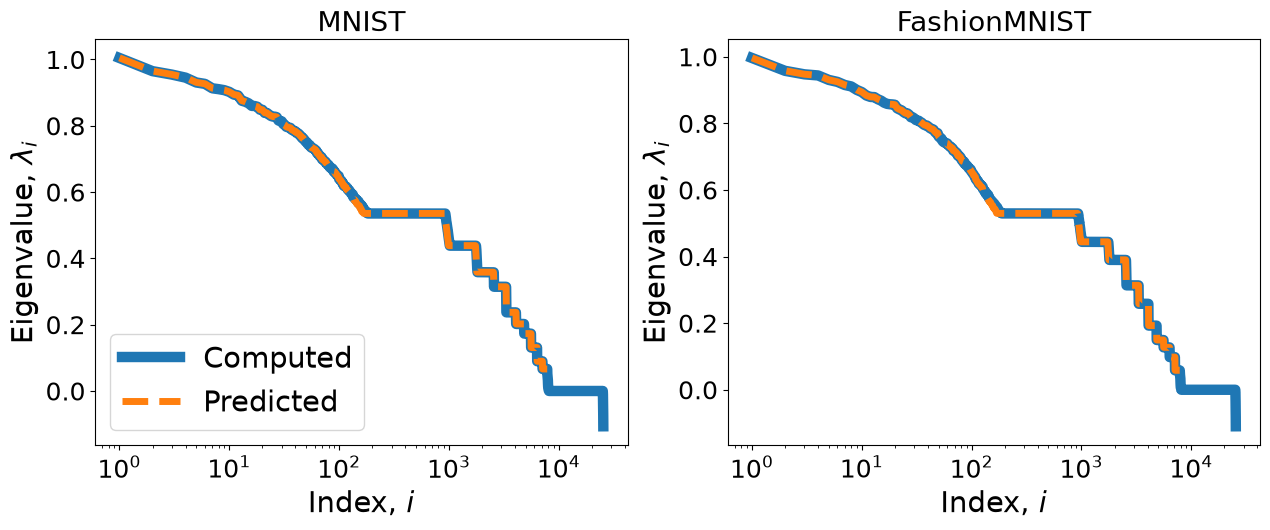

In [24]:
from all_eigvals_shallow import *
source_name = "all_eigvals_shallow"
DATASETS = ("MNIST", "FashionMNIST")

fig, axs = plt.subplots(1, len(DATASETS), figsize=(AX_WIDTH*len(DATASETS), AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))

for Dataset, ax in zip(DATASETS, axs):
    fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
    results = torch.load(fn, weights_only=False, map_location="cpu")
    kwargs, assets, out = results["kwargs"], results["assets"], results["out"]    
    *_, numerical_eigvals, theoretical_eigvals = out
    ax.plot(range(1, len(numerical_eigvals)+1), numerical_eigvals, linewidth=1.5*LINE_WIDTH, label="Computed")
    ax.plot(range(1, len(theoretical_eigvals)+1), theoretical_eigvals, linewidth=LINE_WIDTH, linestyle="--", label="Predicted")
    ax.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax.set_xlabel(r"Index, $i$", fontsize=FONT_SIZE)
    ax.set_ylabel(r"Eigenvalue, $\lambda_i$", fontsize=FONT_SIZE)
    ax.set_title(Dataset, fontsize=20)
    ax.set_xscale("log")
    # ax.grid()

axs[0].legend(loc="lower left", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)

fig.tight_layout()
fn = f"{ASSETS}/{source_name}.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()